<a href="https://colab.research.google.com/github/chenharry66/adversial-audio-experiments/blob/main/perturbation_optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##Setup

In [174]:
#install depencies
!pip install werpy scipy

In [175]:
# import dependncies
import werpy, torch

In [176]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [177]:
from scipy.io import wavfile

rate, data = wavfile.read('/content/drive/MyDrive/FOLDER/01/recording2.wav')

data.dtype

dtype('int16')

In [178]:
clip = data[:160000]

In [179]:
import numpy as np

clip = clip / 32768

In [180]:
def pad_to_target_duration(waveform, duration):
    target = int(duration * rate)
    numToPad = max(0, target - len(waveform))
    waveform = waveform + ([0] * numToPad)
    return waveform

In [181]:
from IPython.display import Audio

audio = Audio(data = clip, rate = rate, normalize=False)
audio

##Model Definition and Establishing a Baseline

We now have our target audio. We will then initialize our frozen ASR model. Eventually after breaking whisper tiny, we can scale to more complex architectures.

In [182]:
from transformers import WhisperProcessor, WhisperForConditionalGeneration

processor = WhisperProcessor.from_pretrained("openai/whisper-tiny")
model = WhisperForConditionalGeneration.from_pretrained("openai/whisper-tiny")

Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

In [183]:
input_features = processor(clip, sampling_rate=rate, return_tensors="pt")["input_features"]
predicted_ids = model.generate(input_features)

In [184]:
transcription = processor.batch_decode(predicted_ids, skip_special_tokens=False)

In [185]:
transcription =  "".join(transcription)

In [186]:
reference = "I must make an admission,” Ivan began. “I never could understand how it’s ‘possible to love one’s neighbors"

In [187]:
import regex as re

def custom_normalize(text):
    clean_text = re.sub(r'[\p{P}\p{S}]', '', text)
    return werpy.normalize(clean_text)

In [188]:
reference = custom_normalize(reference)
transcription = custom_normalize(transcription)

In [189]:
wer = werpy.wer(reference, transcription)
print(f"Baseline Wer: {wer * 100:.2f}%")

Baseline Wer: 33.33%


Our baseline WER measurement is 33%.



## Perturbial Optimization within Whole Audio Timeframe

We can think of perturbial generation as a naive constrained optimization problem, where we are optimizing against some differentiable loss function (in this case we define that loss funciton to be CTC loss) and our constraint is that the SNR for the clip has to be under some limit. From previous experiments,**we define that SNR to be 23dB initially.** We can think of our adverserial perturbation δ as essentially an array of weights where each weight **$w_t$ represents the amplitude of the waveform at time t.** For each iteration of training, we take our initial audio waveform $x$, add $\delta$ to it, and transcribe the result using our frozen model. And then we backpropogate, moving in direction of the loss function's gradient, taking a PGD like approach where we clip back to the boundrayr whenever the SNR exceeds our limit.

In [190]:
audio_rms = np.sqrt(np.mean(clip ** 2))

In [206]:
audio_rms = np.float32(audio_rms)

In [209]:
audio_rms

np.float32(0.00611138)

In [210]:
target_rms = audio_rms/(10**(23/20))

In [212]:
 20 * np.log10(audio_rms/target_rms)

np.float32(23.0)

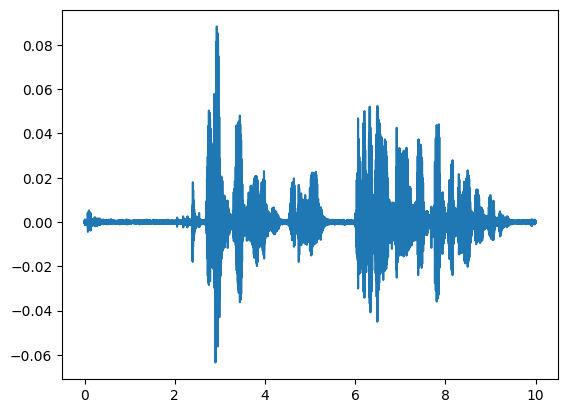

In [194]:
import matplotlib.pyplot as plt

t = np.linspace(0, 10, int(rate * 10), endpoint=False)
plt.plot(t, clip)

In [195]:
clip = pad_to_target_duration(clip.tolist(),30)

In [196]:
from torch import stft

MAX_ITERS = 200
ALPHA = 1e-5

clip = torch.tensor(clip)
delta = torch.zeros_like(clip, requires_grad=True)

labels = processor.tokenizer(reference, return_tensors="pt", return_attention_mask=False)['input_ids']

for p in model.parameters():
    p.requires_grad = False

for i in range(MAX_ITERS):
    # forward pass compute the perturbation and then get the feature feed htrough asr
    perturbation = clip + delta
    window = torch.hann_window(400)
    stft = torch.stft(perturbation, 400, 160, window=window, return_complex=True)
    magnitudes = (stft[..., :-1].abs() ** 2).contiguous()
    mel_filters = torch.from_numpy(processor.feature_extractor.mel_filters).float()
    mel_spec = mel_filters.T @ magnitudes
    log_spec = torch.clamp(mel_spec, min=1e-10).log10()
    log_spec = torch.maximum(log_spec, log_spec.max() - 8.0)
    log_spec = (log_spec + 4.0) / 4.0

    out = model(log_spec.unsqueeze(0), labels=labels, return_tensors="pt")
    loss = out.loss
    print(f"Iteration {i} Loss: {loss.item()}")
    # backward
    loss.backward()
    # update
    with torch.no_grad():
        delta += ALPHA * delta.grad
        current_rms = torch.sqrt(torch.mean(delta**2)) + 1e-6
        print(f"Iteration {i} RMS: {current_rms}")
        if current_rms > target_rms:
            delta *= (target_rms / current_rms)

Iteration 0 Loss: 4.937741279602051
Iteration 0 RMS: 1.1763266229536384e-05
Iteration 1 Loss: 6.224283218383789
Iteration 1 RMS: 2.6112284103874117e-05
Iteration 2 Loss: 6.971934795379639
Iteration 2 RMS: 4.327243004809134e-05
Iteration 3 Loss: 7.586319446563721
Iteration 3 RMS: 6.255492917262018e-05
Iteration 4 Loss: 7.931674480438232
Iteration 4 RMS: 8.325738599523902e-05
Iteration 5 Loss: 8.555197715759277
Iteration 5 RMS: 0.00010480088531039655
Iteration 6 Loss: 8.999384880065918
Iteration 6 RMS: 0.00012685988622251898
Iteration 7 Loss: 9.299884796142578
Iteration 7 RMS: 0.00014929243479855359
Iteration 8 Loss: 9.610013961791992
Iteration 8 RMS: 0.00017203287279698998
Iteration 9 Loss: 9.965450286865234
Iteration 9 RMS: 0.00019505435193423182
Iteration 10 Loss: 10.300719261169434
Iteration 10 RMS: 0.00021831838239450008
Iteration 11 Loss: 10.653840065002441
Iteration 11 RMS: 0.00024185236543416977
Iteration 12 Loss: 10.639793395996094
Iteration 12 RMS: 0.00026573333889245987
Iterat

In [197]:
delta = delta.detach().numpy()
clip = clip.detach().numpy()

In [198]:
aug_audio = clip + delta

In [199]:
#inference (can copy this over for winowed-timefframe alter)
inputs = processor(aug_audio, return_tensors="pt", sampling_rate=rate)
generated_ids = model.generate(input_features=inputs['input_features'])
transcription = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
transcription = custom_normalize(transcription)
wer = werpy.wer(reference, transcription)

In [200]:
print(f"Wer: {wer * 100}%")

Wer: 100.0%


In [213]:
20 * np.log10(np.sqrt(np.mean(clip**2))/np.sqrt(np.mean(delta**2)))

TypeError: mean() received an invalid combination of arguments - got (dtype=NoneType, out=NoneType, axis=NoneType, ), but expected one of:
 * (*, torch.dtype dtype = None)
 * (tuple of ints dim, bool keepdim = False, *, torch.dtype dtype = None)
 * (tuple of names dim, bool keepdim = False, *, torch.dtype dtype = None)


In [214]:
Audio(aug_audio, rate=rate)

## Perturbial Optimization Within Windowed-Timeframes

In [225]:
# 20 buckets for target rms
# iterate over the original array
target_rms = []

for i in range(0, len(clip), 8000):
    # this ur target_rms
    rms = torch.sqrt(torch.mean(clip[i: i+8000]**2))/10**(23/20)
    target_rms.append(rms.item())

In [228]:
from torch import stft

MAX_ITERS = 200
ALPHA = 1e-5

clip = torch.tensor(clip)
delta = torch.zeros_like(clip, requires_grad=True)
target_rms = torch.tensor(target_rms)

labels = processor.tokenizer(reference, return_tensors="pt", return_attention_mask=False)['input_ids']

for p in model.parameters():
    p.requires_grad = False

for i in range(MAX_ITERS):
    # forward pass compute the perturbation and then get the feature feed htrough asr
    perturbation = clip + delta
    window = torch.hann_window(400)
    stft = torch.stft(perturbation, 400, 160, window=window, return_complex=True)
    magnitudes = (stft[..., :-1].abs() ** 2).contiguous()
    mel_filters = torch.from_numpy(processor.feature_extractor.mel_filters).float()
    mel_spec = mel_filters.T @ magnitudes
    log_spec = torch.clamp(mel_spec, min=1e-10).log10()
    log_spec = torch.maximum(log_spec, log_spec.max() - 8.0)
    log_spec = (log_spec + 4.0) / 4.0

    out = model(log_spec.unsqueeze(0), labels=labels, return_tensors="pt")
    loss = out.loss

    print(f"Iteration {i} Loss: {loss.item()}")
    # backward
    loss.backward()
    # update
    with torch.no_grad():
        for j in range(0, len(perturbation), 8000):
            delta[j:j+8000] += ALPHA * delta.grad[j:j+8000]
            current_rms = torch.sqrt(torch.mean(delta[j:j+8000]**2)) + 1e-6
            print(f"Iteration {i}, Group {j//8000} RMS: {current_rms}")
            if current_rms > target_rms[j//8000]:
                delta[j:j+8000]*= (target_rms[j//8000]/ current_rms)

/tmp/ipykernel_1722/1494598353.py:6: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  clip = torch.tensor(clip)


Streaming output truncated to the last 5000 lines.
Iteration 118, Group1 RMS: 0.0007463116780854762
Iteration 118, Group2 RMS: 0.001106180832721293
Iteration 118, Group3 RMS: 0.0002798383357003331
Iteration 118, Group4 RMS: 0.00041870103450492024
Iteration 118, Group5 RMS: 0.0010253791697323322
Iteration 118, Group6 RMS: 0.0006710630259476602
Iteration 118, Group7 RMS: 0.0005132013466209173
Iteration 118, Group8 RMS: 0.0003762280393857509
Iteration 118, Group9 RMS: 0.0005382645758800209
Iteration 118, Group10 RMS: 0.00044909375719726086
Iteration 118, Group11 RMS: 0.00028274135547690094
Iteration 118, Group12 RMS: 0.0009429482161067426
Iteration 118, Group13 RMS: 0.0007832547998987138
Iteration 118, Group14 RMS: 0.0006206264370121062
Iteration 118, Group15 RMS: 0.0005612915265373886
Iteration 118, Group16 RMS: 0.0007756007835268974
Iteration 118, Group17 RMS: 0.000740149465855211
Iteration 118, Group18 RMS: 0.00046546931844204664
Iteration 118, Group19 RMS: 0.0016660438850522041
Iterat

In [229]:
delta = delta.detach().numpy()
clip = clip.detach().numpy()

In [270]:
import random

options = np.arange(0, len(clip), 8000)
options

num = random.randint(0, len(options)-1)
start_index = options[num]
print(20 * np.log10(np.sqrt(np.mean(clip[start_index:start_index+8000]**2))/(np.sqrt(np.mean(delta[start_index:start_index+8000]**2)) + 1e-6)))

num = random.randint(0, len(options))
start_index = options[num]

print(20 * np.log10(np.sqrt(np.mean(clip[start_index:start_index+8000]**2))/((np.sqrt(np.mean(delta[start_index:start_index+8000]**2))) +1e-6)))

-inf
-inf


/tmp/ipykernel_1722/3192060955.py:8: RuntimeWarning: divide by zero encountered in log10
  print(20 * np.log10(np.sqrt(np.mean(clip[start_index:start_index+8000]**2))/(np.sqrt(np.mean(delta[start_index:start_index+8000]**2)) + 1e-6)))
/tmp/ipykernel_1722/3192060955.py:13: RuntimeWarning: divide by zero encountered in log10
  print(20 * np.log10(np.sqrt(np.mean(clip[start_index:start_index+8000]**2))/((np.sqrt(np.mean(delta[start_index:start_index+8000]**2))) +1e-6)))


In [271]:
aug_audio = clip + delta

In [276]:
#inference (can copy this over for winowed-timefframe alter)
inputs = processor(aug_audio, return_tensors="pt", sampling_rate=rate)
generated_ids = model.generate(input_features=inputs['input_features'])
transcription = processor.batch_decode(generated_ids, skip_special_tokens=True)[0]
transcription = custom_normalize(transcription)
wer = werpy.wer(reference, transcription)

In [275]:
print(f"Wer: {wer * 100}%")

Wer: 105.55555555555556%


In [273]:
Audio(aug_audio, rate=rate)

## Psychoacoustic Perturbial Optimizations

In [ ]:
# so now i want to look at how i can make this perturbation inaudible
#